In [ ]:
from tensorflow.keras.datasets import cifar10

In [ ]:
# Load data
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
# Normalize to [0,1]
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

In [ ]:
# Flatten images
X_train = X_train.reshape(X_train.shape[0], -1)
X_test  = X_test.reshape(X_test.shape[0], -1)

In [ ]:
# One-hot encode labels
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, 10)
y_test  = to_categorical(y_test, 10)

print(X_train.shape, y_train.shape)

(50000, 3072) (50000, 10)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout,Input
from tensorflow.keras.optimizers import Adam

In [ ]:
model = Sequential([
    Dense(1024, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.4),
    Dense(512, activation='relu'),
    Dropout(0.4),
    Dense(256, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 1024)           │     3,146,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,805,450 (14.52 MB)

 Trainable params: 3,805,450 (14.52 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,          # stop after 5 bad epochs
    restore_best_weights=True
)


In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=250,                 # give it room to stop early
    batch_size=256,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 137ms/step - accuracy: 0.1891 - loss: 2.2006 - val_accuracy: 0.3341 - val_loss: 1.8635
Epoch 2/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 134ms/step - accuracy: 0.3117 - loss: 1.8920 - val_accuracy: 0.3597 - val_loss: 1.7961
Epoch 3/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 42s 139ms/step - accuracy: 0.3315 - loss: 1.8466 - val_accuracy: 0.3736 - val_loss: 1.7490
Epoch 4/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 136ms/step - accuracy: 0.3494 - loss: 1.8022 - val_accuracy: 0.3850 - val_loss: 1.7207
Epoch 5/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 41s 139ms/step - accuracy: 0.3593 - loss: 1.7738 - val_accuracy: 0.3948 - val_loss: 1.6923
Epoch 6/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 136ms/step - accuracy: 0.3687 - loss: 1.7528 - val_accuracy: 0.4066 - val_loss: 1.6695
Epoch 7/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 146ms/step - accuracy: 0.3747 - loss: 1.7326 - val_accuracy: 0.4179 - val_loss: 1.6437
Epoch 8/250
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 143ms/step - accuracy: 0.3785 -

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.5f}")

Test Accuracy: 0.50320


313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step


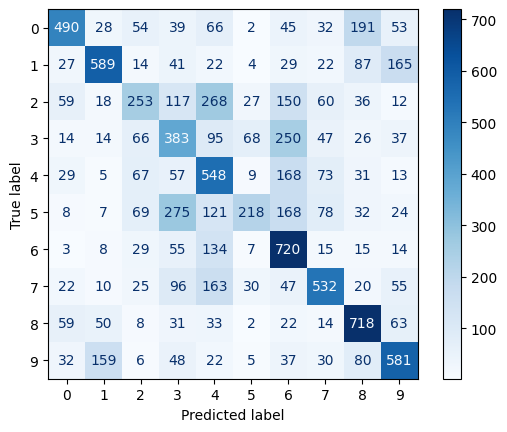

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")
plt.show()

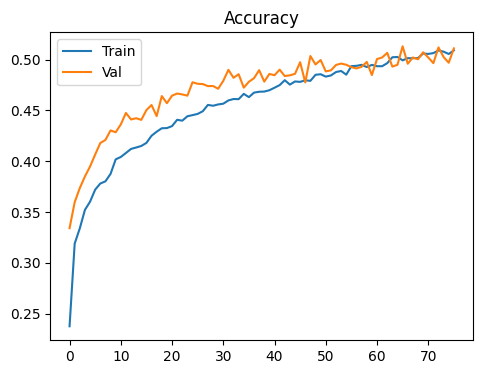

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()
plt.show()

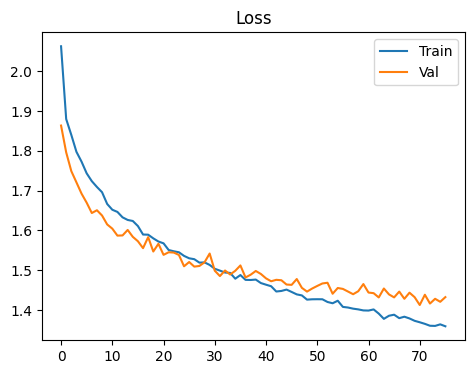

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()

plt.show()
